***LAB 03***

**LOGISTIC REGRESSION**

*Task: Binary classification on Breast Cancer dataset*

Import Required Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Load dataset

In [2]:
data = load_breast_cancer(as_frame=True).frame
print(data.head())
print(data.shape)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

Load dataset from CSV (alternative). First save the dataset as a csv file, then read it back.

In [3]:
#save the dataset to csv
data.to_csv('breast_cancer.csv', index=False)

#load the dataset from csv (for your own file just change the file name/path)
data = pd.read_csv('breast_cancer.csv')
print(data.shape)

(569, 31)


Perform Exploratory Data Analysis (EDA):

In [4]:
#first few rows
data.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
#check for missing values
print(data.isnull().sum().sum())

0


0 means there are no missing values in any column, so no cleaning is needed.

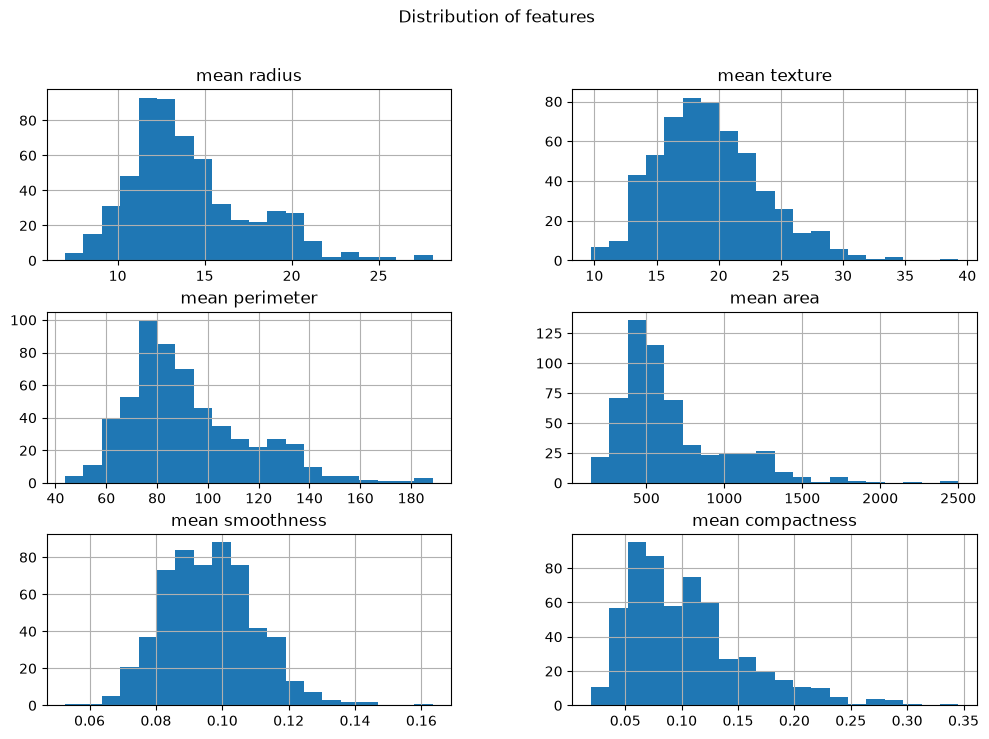

In [6]:
#histograms of the first 6 features
data.drop(columns='target').iloc[:, :6].hist(bins=20, figsize=(12,8))
plt.suptitle('Distribution of features')
plt.show()

target
1    357
0    212
Name: count, dtype: int64


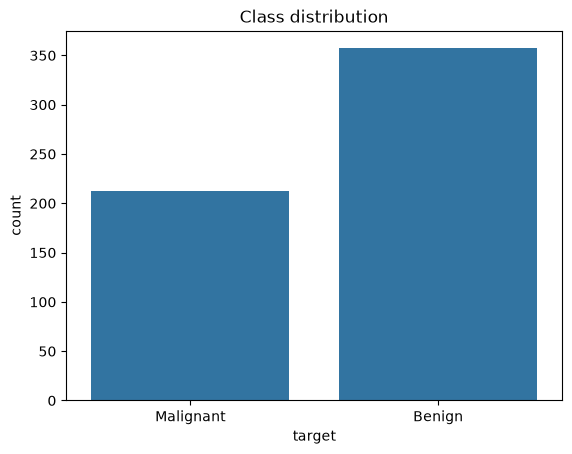

In [7]:
#class distribution (0 = malignant, 1 = benign)
print(data['target'].value_counts())

sns.countplot(x='target', data=data)
plt.xticks([0,1], ['Malignant', 'Benign'])
plt.title('Class distribution')
plt.show()

The classes are not perfectly balanced (more benign than malignant) but not badly imbalanced either, so accuracy is still meaningful, but recall and precision should also be checked.

Data Preprocessing

In [8]:
#split features and labels
X = data.drop(columns='target')
y = data['target']

#train test split (stratify keeps the same class ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#standardize features (fit only on train data so no information leaks from test data)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Implement Logistic Regression

In [9]:
#fit the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

#predict on test data
y_pred = model.predict(X_test)

Evaluate the model

In [10]:
#Accuracy
print('Accuracy =', accuracy_score(y_test, y_pred))

Accuracy = 0.9824561403508771


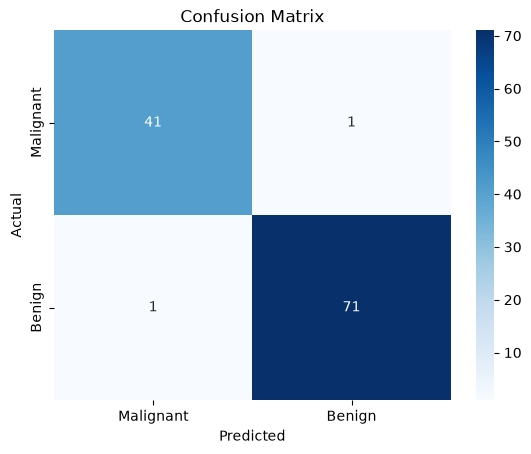

In [11]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant','Benign'], yticklabels=['Malignant','Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [12]:
#Precision, Recall, F1-score
print(classification_report(y_test, y_pred, target_names=['Malignant','Benign']))

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



The model gives high accuracy on the test data. In the confusion matrix, the off-diagonal boxes are the mistakes.

False negatives (malignant predicted as benign) are the most dangerous mistakes in medical diagnosis, so recall of the malignant class is the most important number here. Precision tells how many predicted cases were really correct, and F1-score is the balance of both.

Logistic regression works well here because the classes are almost linearly separable after standardizing the features.